In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('pandas_orders.csv', parse_dates=['order_date', 'signup_date'])
df

,order_id,user_id,user_name,segment,signup_date,home_city,city,region,order_date,channel,product,category,price,quantity,discount_pct,order_total_rub,status,delivery_days,promo_code
0,50387,22,Егор Соколова,regular,2024-05-21,Москва,Москва,Центр,2026-01-02,marketplace,Наушники,Техника,6030.0,1,5,5728.5,completed,6.0,WELCOME
1,50480,25,Кира Орлов,regular,2025-09-14,Москва,Москва,Центр,2026-01-02,app,Какао 300 г,Напитки,400.0,1,5,380.0,completed,1.0,WELCOME
2,50309,51,Вера Миронов,regular,2024-10-18,Краснодар,Краснодар,Юг,2026-01-03,website,Планшет,Техника,27870.0,1,0,27870.0,completed,4.0,NaN
3,50234,95,Рита Кузнецов,new,2024-06-02,Екатеринбург,Санкт-Петербург,Северо-Запад,2026-01-04,website,Фильтр для воды,Дом,1680.0,1,10,1512.0,completed,2.0,SPRING
4,50282,89,Кира Петров,regular,2025-06-06,Краснодар,Казань,Поволжье,2026-01-04,website,Настольная лампа,Дом,3030.0,1,0,3030.0,completed,2.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
502,50417,22,Егор Соколова,regular,2024-05-21,Москва,Новосибирск,Сибирь,2026-09-27,app,Кофе молотый 250 г,Напитки,460.0,4,10,1656.0,completed,3.0,SPRING
503,50195,93,Ольга Зайцев,regular,2025-11-26,Екатеринбург,Екатеринбург,Урал,2026-09-28,app,Кофе молотый 250 г,Напитки,480.0,1,0,480.0,completed,5.0,NaN
504,50069,10,Лев Соколова,regular,2024-08-28,Москва,Москва,Центр,2026-09-29,marketplace,Наушники,Техника,5910.0,2,0,11820.0,completed,5.0,NaN
505,50082,35,Вера Кузнецов,regular,2024-05-28,Москва,Москва,Центр,2026-09-29,app,Какао 300 г,Напитки,440.0,1,0,440.0,completed,2.0,NaN


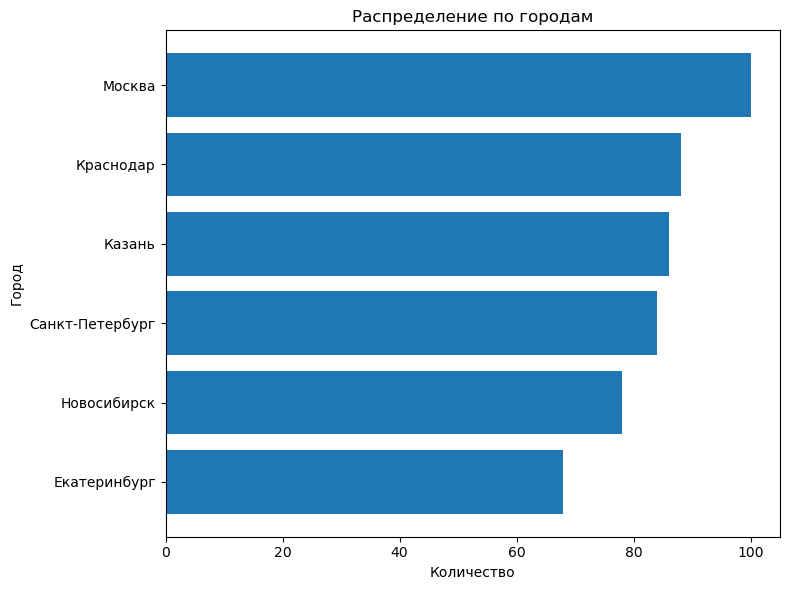

In [ ]:
counts = df['city'].value_counts().sort_values()  

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(counts.index, counts.values)
ax.set_xlabel('Количество')
ax.set_ylabel('Город')
ax.set_title('Распределение по городам')
plt.tight_layout()
plt.show()

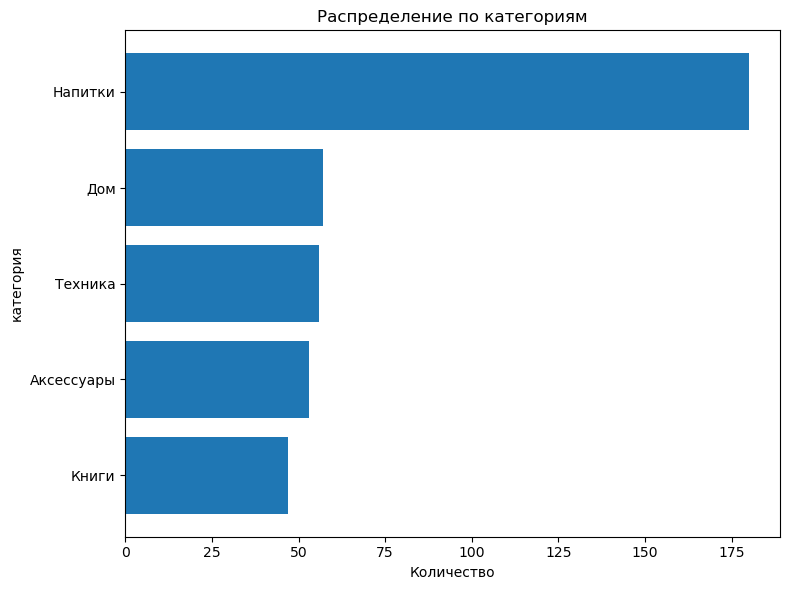

In [5]:
counts = df['category'][df['status']=='completed'].value_counts().sort_values()  

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(counts.index, counts.values)
ax.set_xlabel('Количество')
ax.set_ylabel('категория')
ax.set_title('Распределение по категориям')
plt.tight_layout()
plt.show()

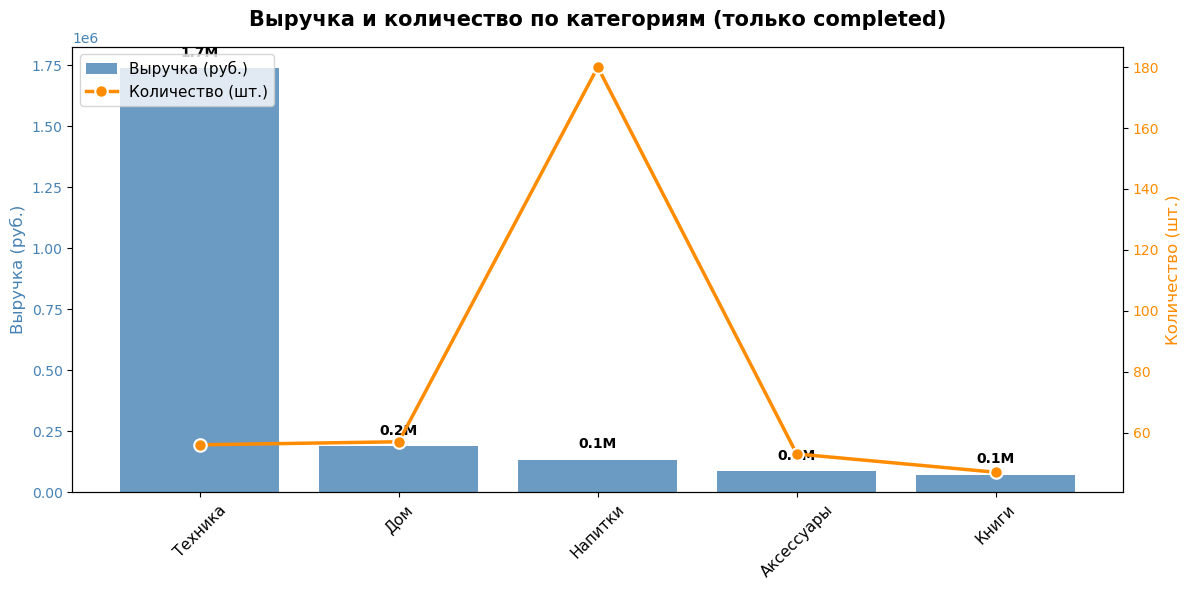

In [ ]:

df['revenue'] = df['price'] * df['quantity']
rev = df[df['status']=='completed'].groupby('category')['revenue'].sum().sort_values(ascending=False)

counts = df[df['status']=='completed']['category'].value_counts()
counts = counts.reindex(rev.index) 

fig, ax1 = plt.subplots(figsize=(12, 6))

bars = ax1.bar(rev.index, rev.values, color='steelblue', alpha=0.8, label='Выручка (руб.)')
ax1.set_ylabel('Выручка (руб.)', color='steelblue', fontsize=12)
ax1.tick_params(axis='y', labelcolor='steelblue')
ax1.tick_params(axis='x', rotation=45, labelsize=11)

max_rev = rev.max()
for bar in bars:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, yval + max_rev*0.02, 
             f'{yval/1e6:.1f}M', ha='center', va='bottom', fontsize=10, fontweight='bold')

ax2 = ax1.twinx()
ax2.plot(counts.index, counts.values, color='darkorange', marker='o', linewidth=2.5, 
         markersize=9, zorder=3, markeredgecolor='white', markeredgewidth=1.5, 
         label='Количество (шт.)')
ax2.set_ylabel('Количество (шт.)', color='darkorange', fontsize=12)
ax2.tick_params(axis='y', labelcolor='darkorange')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=11)

plt.title('Выручка и количество по категориям (только completed)', fontsize=15, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

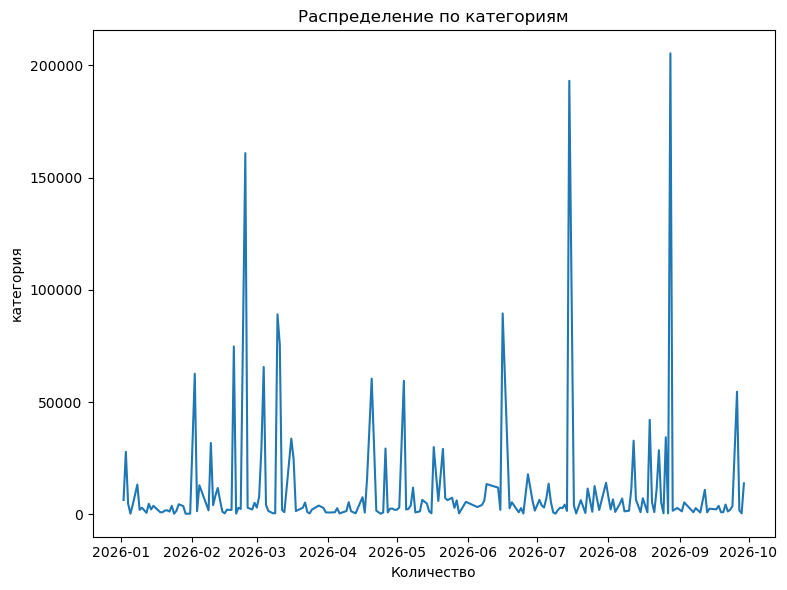

In [25]:
revenue = df[df['status']=='completed'].groupby('order_date')['revenue'].sum()

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(revenue.index, revenue.values)
ax.set_xlabel('Количество')
ax.set_ylabel('категория')
ax.set_title('Распределение по категориям')
plt.tight_layout()
plt.show()

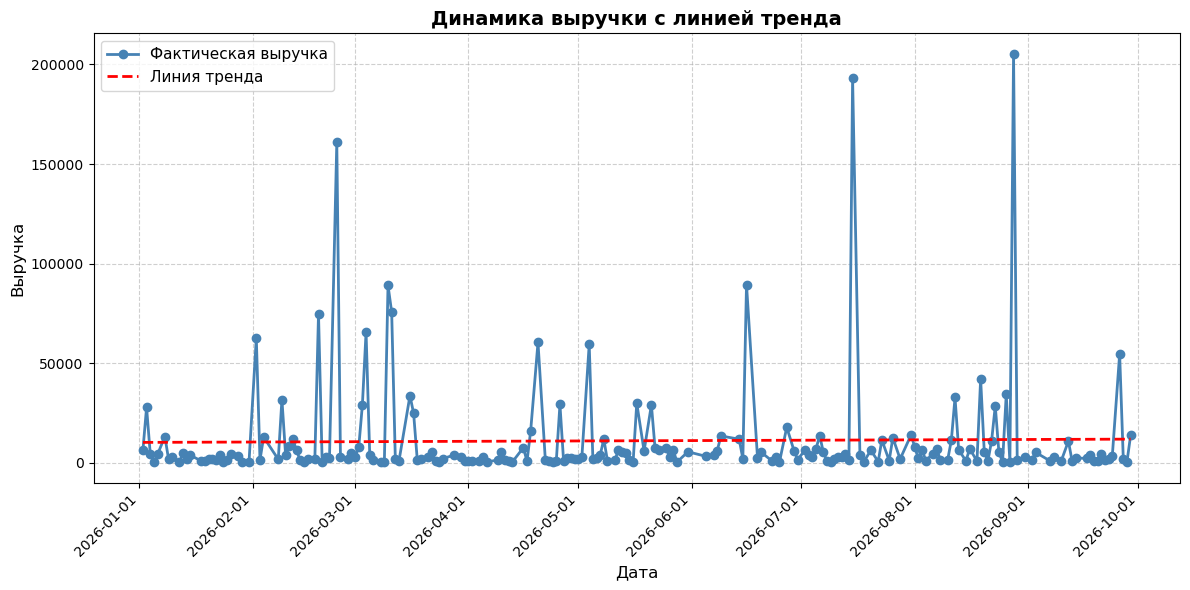

In [26]:
import matplotlib.dates as mdates
import numpy as np

revenue = df[df['status']=='completed'].groupby('order_date')['revenue'].sum().sort_index()

revenue.index = pd.to_datetime(revenue.index)

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(revenue.index, revenue.values, marker='o', color='steelblue', 
        label='Фактическая выручка', linewidth=2)


x_num = mdates.date2num(revenue.index)
z = np.polyfit(x_num, revenue.values, 1) # 1 = линейный тренд
p = np.poly1d(z)

ax.plot(revenue.index, p(x_num), color='red', linestyle='--', 
        linewidth=2, label='Линия тренда')

ax.set_xlabel('Дата', fontsize=12)
ax.set_ylabel('Выручка', fontsize=12)
ax.set_title('Динамика выручки с линией тренда', fontsize=14, fontweight='bold')

ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
ax.xaxis.set_major_locator(mdates.AutoDateLocator())
plt.xticks(rotation=45, ha='right')

ax.grid(True, linestyle='--', alpha=0.6)
ax.legend(fontsize=11)

plt.tight_layout()
plt.show()

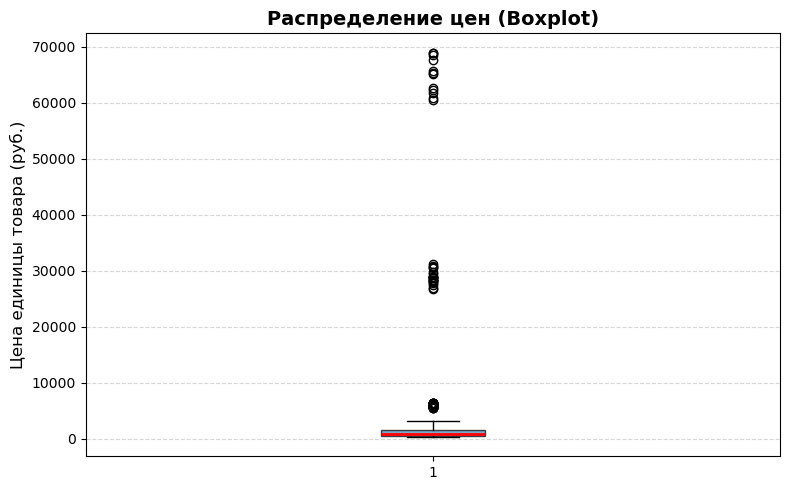

     order_id  user_id       user_name  segment signup_date     home_city  \
91      50408       26     Лев Егорова  regular  2024-12-19        Казань   
132     50321       78  Павел Фёдорова  regular  2024-01-17  Екатеринбург   
448     50092       48  Степан Иванова  regular  2024-09-25   Новосибирск   

             city    region order_date      channel  product category  \
91         Казань  Поволжье 2026-02-19          app  Ноутбук  Техника   
132  Екатеринбург      Урал 2026-03-11  marketplace  Ноутбук  Техника   
448   Новосибирск    Сибирь 2026-08-28          app  Ноутбук  Техника   

       price  quantity  discount_pct  order_total_rub     status  \
91   68930.0         1            15          58590.5  completed   
132  68900.0         1             0          68900.0  completed   
448  68440.0         3             0         205320.0  completed   

     delivery_days promo_code   revenue  
91             1.0        VIP   68930.0  
132            4.0        NaN   68900.0  

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(df['price'].dropna(), vert=True, patch_artist=True,
           boxprops=dict(facecolor='steelblue', alpha=0.7),
           medianprops=dict(color='red', linewidth=2))
ax.set_ylabel('Цена единицы товара (руб.)', fontsize=12)
ax.set_title('Распределение цен (Boxplot)', fontsize=14, fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.5, axis='y')
plt.tight_layout()
plt.show()

top3 = df.nlargest(3, 'price')
print(top3)

In [28]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Q1 (25-й перцентиль): {Q1:.2f}")
print(f"Q3 (75-й перцентиль): {Q3:.2f}")
print(f"IQR (Q3 - Q1):        {IQR:.2f}")
print(f"Нижняя граница:       {lower_bound:.2f}")
print(f"Верхняя граница:      {upper_bound:.2f}")

Q1 (25-й перцентиль): 460.00
Q3 (75-й перцентиль): 1605.00
IQR (Q3 - Q1):        1145.00
Нижняя граница:       -1257.50
Верхняя граница:      3322.50


In [29]:
df['price'][df['price'] > upper_bound]

0       6030.0
2      27870.0
9       6270.0
33     28010.0
39      5590.0
        ...   
446     5550.0
448    68440.0
468     5830.0
500    26680.0
504     5910.0
Name: price, Length: 73, dtype: float64

In [32]:
low = df['price'].quantile(0.05)
upp = df['price'].quantile(0.95)
df[(df['price'] < low) | (df['price'] > upp)]

,order_id,user_id,user_name,segment,signup_date,home_city,city,region,order_date,channel,product,category,price,quantity,discount_pct,order_total_rub,status,delivery_days,promo_code,revenue
38,50503,9999,NaN,NaN,NaT,NaN,Новосибирск,Сибирь,2026-01-24,app,Чай зелёный 100 г,Напитки,320.0,1,0,320.0,completed,9.0,NaN,320.0
49,50057,38,Егор Егорова,regular,2025-03-05,Екатеринбург,Екатеринбург,Урал,2026-01-29,marketplace,Чай зелёный 100 г,Напитки,320.0,1,5,304.0,completed,1.0,WELCOME,320.0
56,50223,62,Павел Егорова,regular,2025-08-20,Екатеринбург,Новосибирск,Сибирь,2026-02-02,website,Ноутбук,Техника,62640.0,1,15,53244.0,completed,1.0,VIP,62640.0
70,50395,26,Лев Егорова,regular,2024-12-19,Казань,Казань,Поволжье,2026-02-09,app,Планшет,Техника,30860.0,1,5,29317.0,completed,5.0,WELCOME,30860.0
82,50339,46,Павел Соколова,regular,2024-06-27,Краснодар,Краснодар,Юг,2026-02-14,website,Ноутбук,Техника,62230.0,2,0,124460.0,returned,7.0,NaN,124460.0
91,50408,26,Лев Егорова,regular,2024-12-19,Казань,Казань,Поволжье,2026-02-19,app,Ноутбук,Техника,68930.0,1,15,58590.5,completed,1.0,VIP,68930.0
97,50053,66,Борис Фёдорова,regular,2024-01-30,Казань,Казань,Поволжье,2026-02-24,website,Ноутбук,Техника,65080.0,1,0,65080.0,completed,2.0,NaN,65080.0
98,50055,94,Павел Соколова,regular,2024-08-28,Краснодар,Краснодар,Юг,2026-02-24,marketplace,Планшет,Техника,30430.0,1,10,27387.0,completed,1.0,SPRING,30430.0
99,50189,47,Рита Кузнецов,regular,2024-02-27,Москва,Москва,Центр,2026-02-24,app,Ноутбук,Техника,65370.0,1,0,65370.0,completed,1.0,NaN,65370.0
100,50425,69,Дина Зайцев,regular,2025-10-23,Краснодар,Краснодар,Юг,2026-02-24,app,Чай зелёный 100 г,Напитки,310.0,1,0,310.0,pending,NaN,NaN,310.0


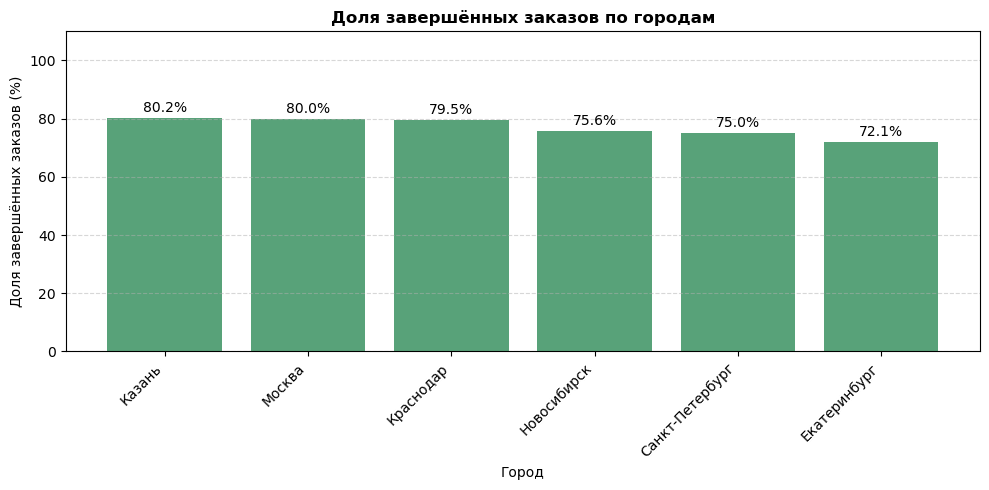

In [33]:
share = (df.assign(is_completed=df['status'] == 'completed')
           .groupby('city')['is_completed']
           .mean() * 100)  
share = share.sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(share.index, share.values, color='seagreen', alpha=0.8)

for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=10)

ax.set_ylabel('Доля завершённых заказов (%)')
ax.set_xlabel('Город')
ax.set_title('Доля завершённых заказов по городам', fontweight='bold')
ax.set_ylim(0, 110)
ax.grid(True, axis='y', linestyle='--', alpha=0.5)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()
